# Keepon pro: cabeza robótica social de 3 GDL

**Informe técnico · µTP Robótica Social · Robótica II · FIUNA · 2026**

Cabeza con ojos sobre un cuello de 3 grados de libertad (yaw, pitch, roll), con una cámara en la cara y un buzzer pasivo.
Detecta personas, las sigue con la mirada, responde a saludos, a miradas y a camisetas de Olimpia y Cerro, y tiene cuatro
modos de personalidad. Toda la percepción y la decisión corren en una Raspberry Pi 5; una ESP32-C3 mueve los servos y toca los sonidos.

| | |
|---|---|
| **Integrantes** | <span style="background:#fff3b0;padding:2px 4px">**[A COMPLETAR POR EL GRUPO]**</span> |
| **Repositorio** | https://github.com/HecVelaz/keepon-pro |
| **Video de demostración** | <span style="background:#fff3b0;padding:2px 4px">**[A COMPLETAR POR EL GRUPO]**</span> (enlace, ≤ 3 min) |
| **CAD del mecanismo** | `docs/diseno_v6/` en el repositorio (modelo vigente v6 R4) |
| **Guía completa (PDF)** | `docs/guia/Guia_Keepon_pro.pdf` en el repositorio |

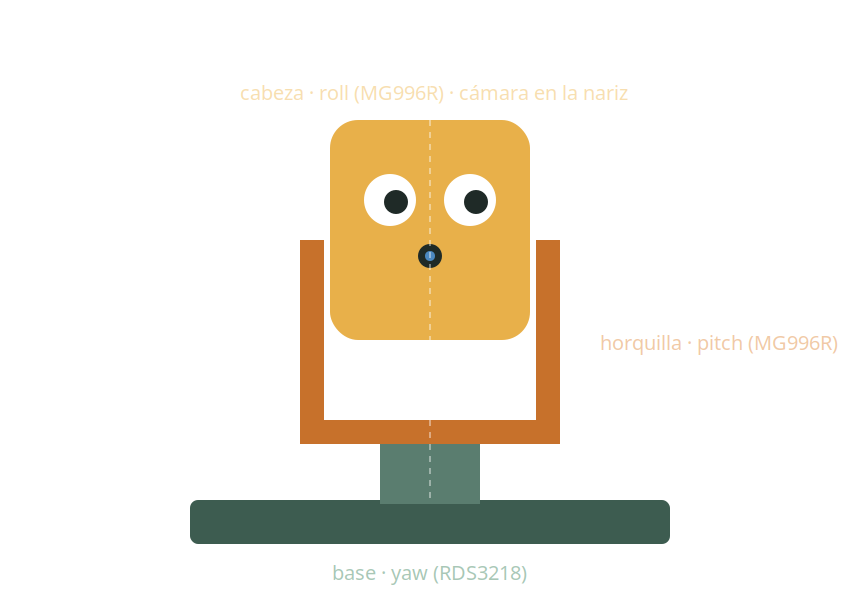

**Contenido:** 1. Resumen · 2. Mecanismo · 3. Electrónica y conexiones · 4. Control de los motores · 5. Modelos de IA ·
6. Definición operativa de los eventos · 7. Arquitectura · 8. Tabla de prioridades y árbitro · 9. Diagramas de estados de los modos ·
10. Parámetros · 11. Resultados · 12. Aportes individuales · 13. Referencias

> Las celdas de código ya están ejecutadas: el informe se lee sin correr nada. Si se ejecutan en Colab, descargan el repositorio
> público y leen los parámetros reales de `config.yaml`; no hace falta el robot.

In [1]:
# Preparación: descarga el repositorio público y carga config.yaml, que concentra TODOS los parámetros del robot.
import os, subprocess, sys
RAMA = "camisetas"   # cambiar a "main" cuando se integren los PR #3, #4 y #5
if not os.path.exists("keepon-pro"):
    subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", RAMA,
                    "https://github.com/HecVelaz/keepon-pro.git"], check=True)
sys.path.insert(0, "keepon-pro")

import yaml, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 80)
cfg = yaml.safe_load(open("keepon-pro/config.yaml", encoding="utf-8"))
print("config.yaml cargado con las secciones:", ", ".join(cfg))

config.yaml cargado con las secciones: neck, serial, camera, control, perception, camiseta, eventos, buzzer, sounds, priorities, cooldowns, gaze, focus, curiosidad, modos, observer, greeting


## 1. Resumen

### Qué percibe y cómo responde

| Situación | Evento | Respuesta del robot |
|---|---|---|
| No hay nadie | — | **Observador**: mira alrededor saltando de un punto a otro con pausas de 2 s |
| Aparece una persona | PERSONA | **Seguimiento**: centra su rostro con yaw y pitch; con varias personas prioriza a quien lo mira |
| La persona saluda con la mano | SALUDO | 3 cabeceos + sonido tipo R2D2 |
| Lleva la camiseta de Olimpia | CAMISETA_OLIMPIA | Silba la polca de Olimpia **sin dejar de seguirla** |
| Lleva la camiseta de Cerro | CAMISETA_CERRO | Abucheo (silbido de reprobación) |
| La persona lo mira | ME_MIRA | Según el modo: Tímido aparta la mirada; Atrevido levanta el mentón |
| La persona se va del campo visual | SALIENDO | En modo Maleducado: silbido de piropo, una vez por salida |
| Se queda quieta 3 s | — | **Curiosidad** (extra): inclina la cabeza 15° en roll |
| El operador manda un comando | OPERADOR | STOP enclavado, cambio de modo con beep, sonidos, volumen, HOME |

### El sistema de un vistazo

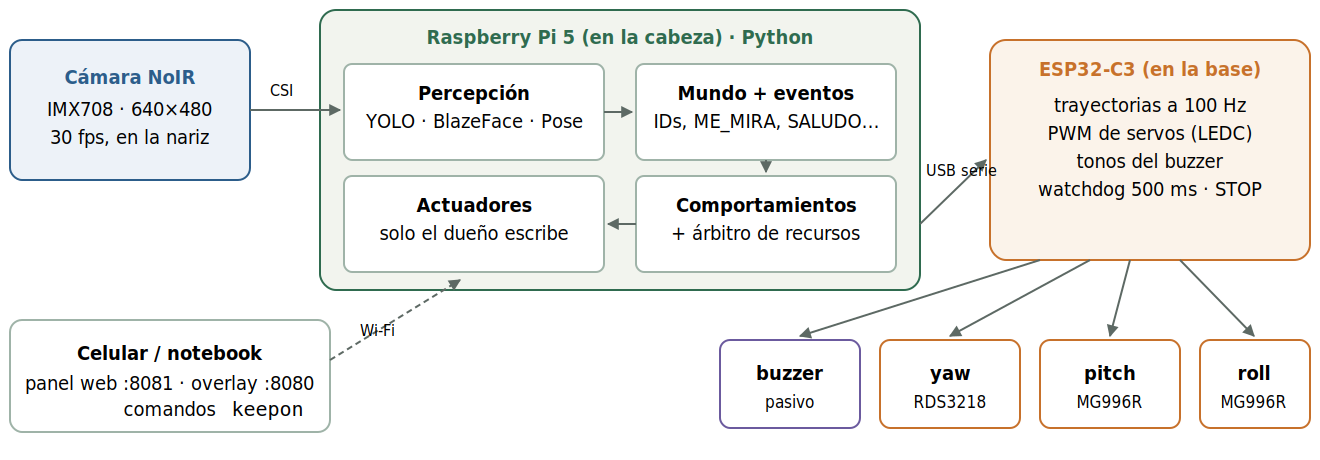

*Figura 1. La Pi hace toda la inteligencia; la ESP32 solo ejecuta movimientos suaves y sonidos, de forma segura y sin bloquear.*

### Cómo avanzó el proyecto

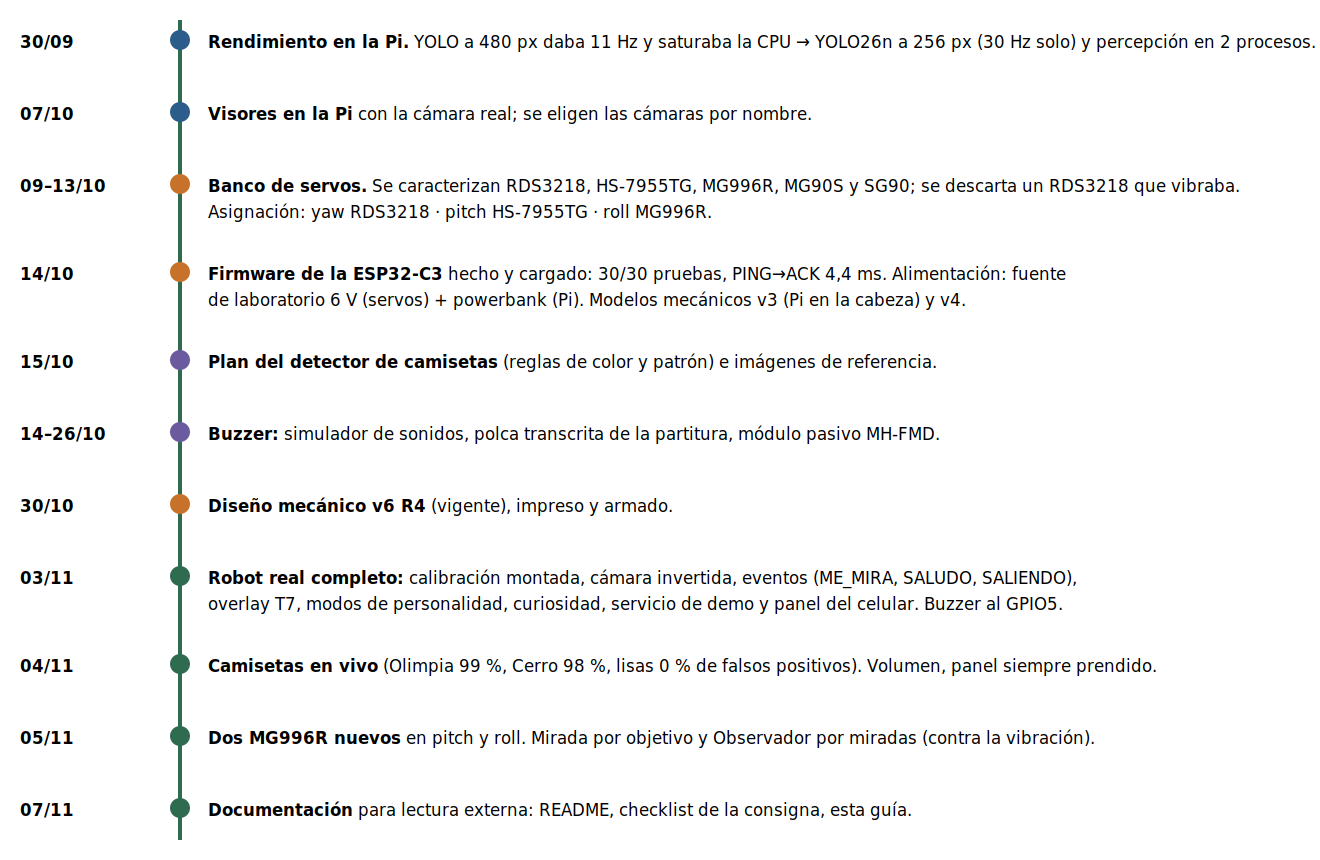

*Figura 2. Línea de tiempo. Primero se escribió el robot completo en Python con un ESP32 simulado y personas sintéticas, para
probar el árbitro y los comportamientos sin mecánica; el firmware se escribió después como copia del simulador.*

## 2. Mecanismo

Estructura impresa en 3D, diseñada por el grupo (CadQuery/Python + SolidWorks). El modelo vigente es el **v6 R4**, armado desde el 03/11.

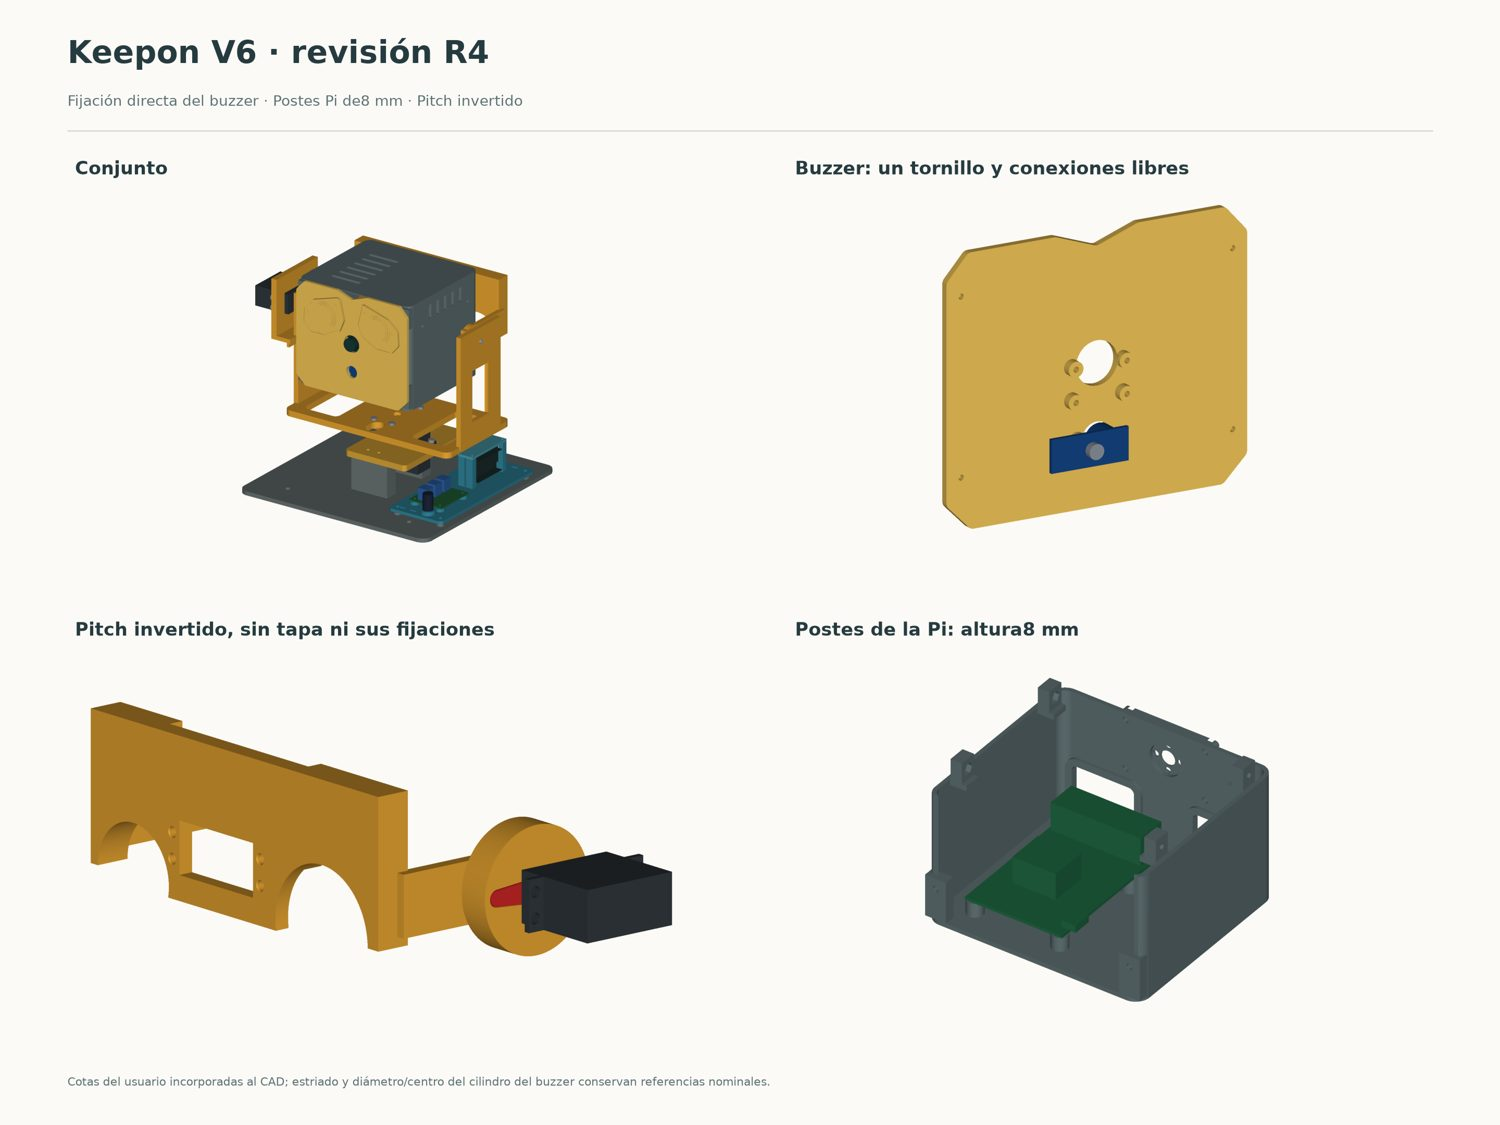

*Figura 3. Keepon v6 R4: conjunto, cara con el buzzer, cuna de pitch con su servo y caja de la cabeza con la Pi.*

### Cadena cinemática

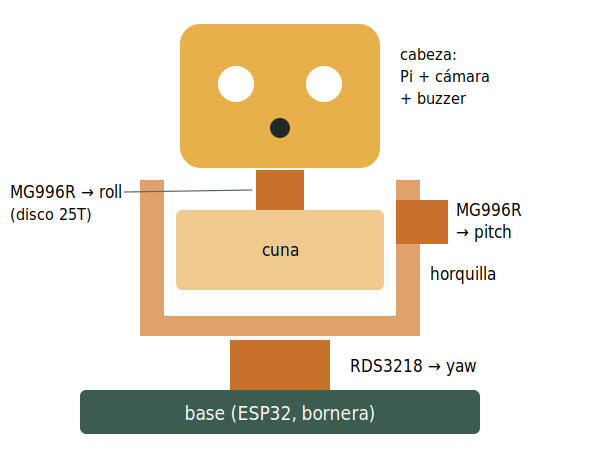

| Eje | Servo | Va en | Mueve | Recorrido |
|---|---|---|---|---|
| **yaw** (guiñada) | DSSERVO RDS3218 | la base | la horquilla | ±70° |
| **pitch** (cabeceo) | TowerPro MG996R | la horquilla | la cuna | −20° / +30° |
| **roll** (alabeo) | TowerPro MG996R | la cuna | la cabeza (disco de 25T) | ±20° |

Los ejes de pitch y roll se cruzan en (0, 0, 163) mm y el centro óptico de la cámara está a la misma altura: al girar, la cámara rota
sobre sí misma y no se desplaza, lo que simplifica el control de la mirada.

### Evolución del diseño

| Versión | Fecha | Qué cambió y por qué |
|---|---|---|
| v2 | oct. | Primer cuello completo de 3 ejes. |
| v3 | 14/10 | **Pi dentro de la cabeza** y la cámara como nariz: la cinta de la cámara mide ~150 mm y no llega a la base. Pitch con +30° arriba y −20° abajo (más abajo la cara toca el plato). |
| v4 | 14/10 | Eje de pitch sobre el de yaw y base en U (el vuelco sobre el yaw baja a 0,81 kgf·cm); caja base con powerbank, bornes de la fuente, interruptor y bornera. |
| **v6 R4** | 30/10 | Vigente y armado. Disco de 25T para el roll, postes de la Pi de 8 mm, brazo de pitch invertido, buzzer detrás de la cara. Sin interferencias en 45 poses nominales. |

No se consiguió rodamiento de yaw: el plato se apoya solo en el horn del RDS3218 (≈ 330 g, ≈ 1,3 kgf·cm de vuelco), por eso el peso
tiene que quedar centrado sobre ese eje.

## 3. Electrónica y conexiones

### Componentes

| Componente | Función y datos clave |
|---|---|
| **Raspberry Pi 5**, 4 GB | Percepción, decisión y control. Ubuntu 24.04 + ROS 2 Jazzy (ROS 2 solo para leer la cámara). Va en la cabeza. |
| **Camera Module 3 NoIR** (IMX708) | 640×480 a 30 fps, montada invertida. Campo útil ≈ 37° × 28° (a 640×480 se recorta el sensor). Sin filtro IR: los colores se corren. |
| **ESP32-C3-DevKitM-1** (clon CH340) | Pulsos de los servos y tonos del buzzer. USB serie a 115 200 baudios con la Pi. |
| **DSSERVO RDS3218** (yaw) | 270°. Sin pulso mantiene la posición. Sin tope mecánico: los límites de software protegen el cableado. |
| **2 × TowerPro MG996R** (pitch y roll) | ~10 kgf·cm a 6 V. **Sin pulso quedan flojos**: la cabeza cae si se corta el pulso o los 6 V. |
| **Buzzer pasivo MH-FMD** | Frecuencia variable (melodías). Trae su transistor PNP: VCC a 3V3, activo en bajo. |
| **Powerbank Xiaomi PB2020MI** | Alimenta la Pi: 20 000 mAh, 5 V / 3 A. Dura ~9 h. |
| **Fuente de laboratorio** | Servos a 6,0 V con límite de corriente de 4–5 A (uso normal 2–3 A; un servo trabado pide 2,5–4,2 A). |

### Diagrama eléctrico

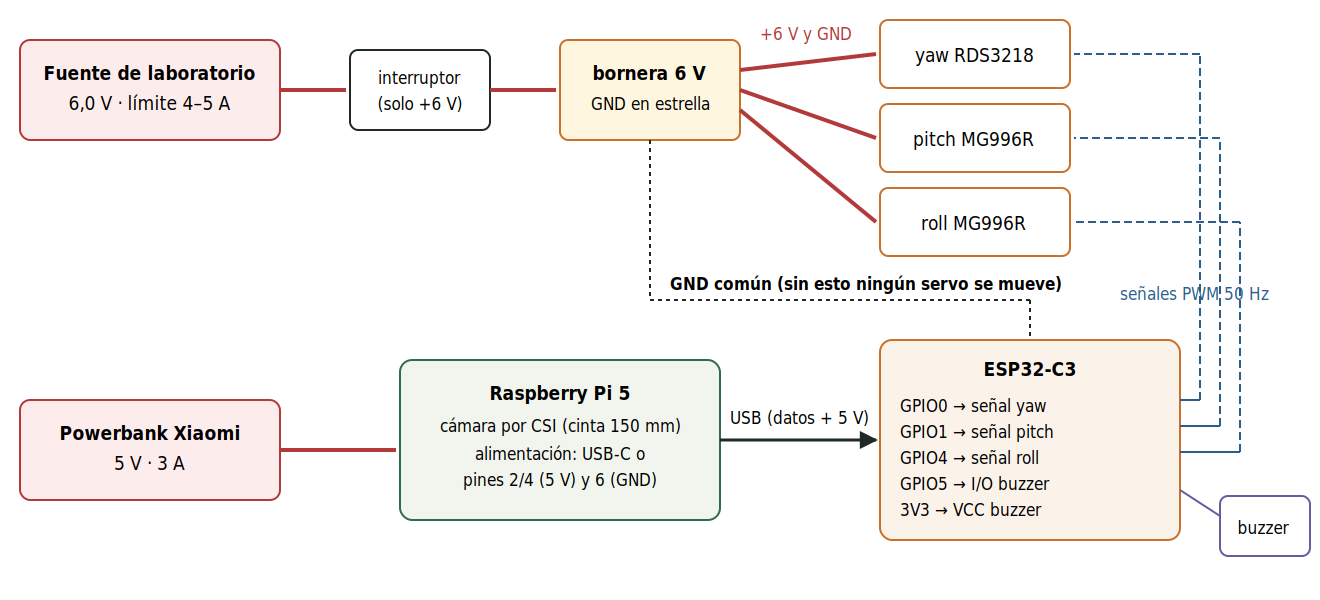

*Figura 4. Dos fuentes separadas, unidas solo por el GND. La ESP32 se alimenta por el USB de la Pi; los servos solo toman señal de la ESP32.
Sin GND común entre la ESP32 y la fuente de los servos, ningún servo se mueve.*

### Pines de la ESP32-C3

| Pin | Uso | Nota |
|---|---|---|
| GPIO0 | servo yaw | PWM 50 Hz, 14 bits |
| GPIO1 | servo pitch | mismo timer LEDC que yaw |
| GPIO4 | servo roll | antes GPIO3, que está junto al GPIO2 (de strapping) |
| GPIO5 | buzzer (I/O) | timer LEDC aparte; antes GPIO10, que dejó de sonar con la cabeza armada |
| GPIO20 / 21 | UART0 (USB serie) | reservados |
| GPIO2 / 8 / 9 | strapping | **no usar**: definen el modo de arranque |
| GPIO18 / 19 | USB nativo | no usar |

**Encendido:** primero el powerbank (Pi), la cabeza cerca de HOME, después los 6 V. **Apagado:** al revés. Los servos no tienen
realimentación: el primer pulso los lleva a HOME a toda velocidad, así que conviene que la cabeza ya esté cerca.

**¿Por qué fuente de laboratorio + powerbank?** Los servos generan picos de corriente y ruido; compartiendo fuente con la Pi, esta podría
reiniciarse por caída de tensión. La consigna pide "alimentación propia", no batería: la LiPo y los reguladores salieron del diseño.

## 4. Control de los motores

Un servo de hobby recibe un pulso cada 20 ms; el **ancho** del pulso indica el ángulo. No informan su posición: el control es en lazo
abierto, por eso cada servo se caracterizó en un banco de pruebas.

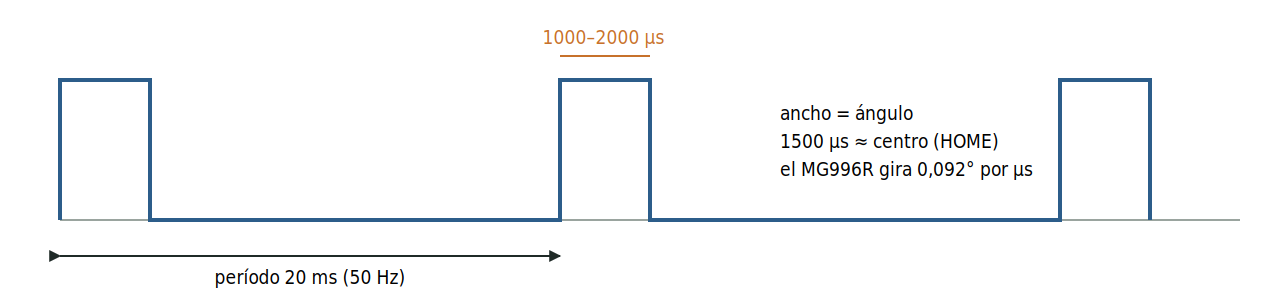

*Figura 5. Señal de un servo, generada por el periférico LEDC de la ESP32.*

La Pi manda **referencias** de ángulo; la ESP32 genera la trayectoria suave hasta ellas a 100 Hz, respetando límites de posición,
velocidad y aceleración. Una referencia nueva **reemplaza** a la anterior: no se encolan movimientos.

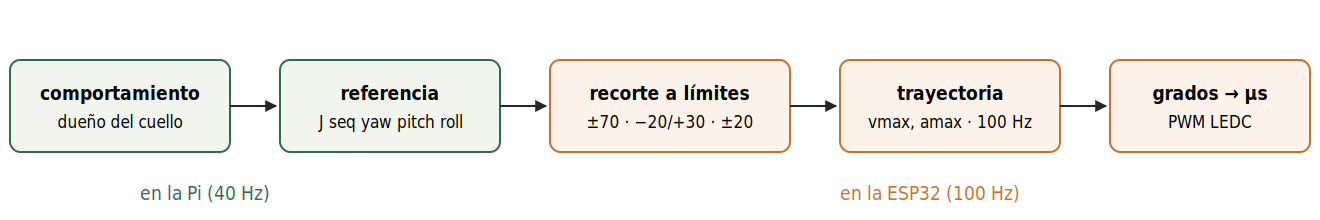

*Figura 6. Cadena de control de un eje.*

**Conversión de grados a microsegundos:** pulso [µs] = centro + signo × ángulo / (grados por µs), recortado a [min, max].
El **signo** deja la misma convención para los tres ejes (yaw + = derecha, pitch + = arriba, roll + = horario visto desde atrás).
La celda siguiente calcula la tabla con los valores reales de `config.yaml`.

In [2]:
# Calibración de cada servo (neck.servos) y conversión grados -> microsegundos, igual que el firmware.
def grados_a_us(eje, angulo):
    s = cfg["neck"]["servos"][eje]
    k = s["grados_por_us"]
    d = s["signo"] * angulo
    if isinstance(k, list):          # yaw: un valor para cada lado de 1500 µs
        k = k[0] if d < 0 else k[1]
    us = s["centro_us"] + d / k
    return min(max(us, s["min_us"]), s["max_us"])

servos = pd.DataFrame(cfg["neck"]["servos"]).T[["centro_us", "grados_por_us", "min_us", "max_us", "signo"]]
servos["límites [°]"] = [str(cfg["neck"]["limits"][e]) for e in servos.index]
display(servos)

filas = []
for e in ("yaw", "pitch", "roll"):
    lo, hi = cfg["neck"]["limits"][e]
    filas.append({"eje": e, f"mínimo": f"{lo:+g}° → {grados_a_us(e, lo):.0f} µs",
                  "centro": f"0° → {grados_a_us(e, 0):.0f} µs", f"máximo": f"{hi:+g}° → {grados_a_us(e, hi):.0f} µs"})
print("Pulso en los extremos y en el centro de cada eje:")
display(pd.DataFrame(filas).set_index("eje"))

,centro_us,grados_por_us,min_us,max_us,signo,límites [°]
pitch,1500.0,0.092,1100.0,1800.0,-1.0,"[-20.0, 30.0]"
yaw,1500,"[0.13, 0.136]",950,2020,-1,"[-70.0, 70.0]"
roll,1500,0.092,1000,2000,-1,"[-20.0, 20.0]"


Pulso en los extremos y en el centro de cada eje:


,mínimo,centro,máximo
eje,,,
yaw,-70° → 2015 µs,0° → 1500 µs,+70° → 962 µs
pitch,-20° → 1717 µs,0° → 1500 µs,+30° → 1174 µs
roll,-20° → 1717 µs,0° → 1500 µs,+20° → 1283 µs


### Perfil de velocidad

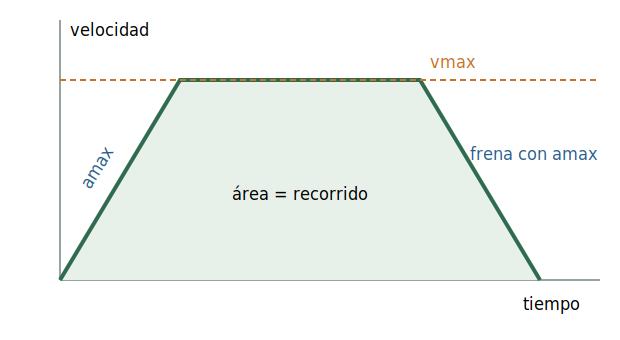

Cada eje sigue un perfil **trapezoidal**: acelera con `amax` hasta `vmax`, avanza y frena a tiempo para llegar exactamente al objetivo
(si el recorrido es corto, el trapecio se vuelve triángulo). El cálculo es discreto y exacto (`keepon/trajectory.py`, fórmula cerrada
`_v_max_to_stop`): las posiciones enviadas nunca superan `amax` y el último paso cae justo en el objetivo. El firmware tiene una copia
en C++ y 36+ tests comparan las dos implementaciones paso a paso. La celda siguiente usa el mismo código para simular un giro de yaw.

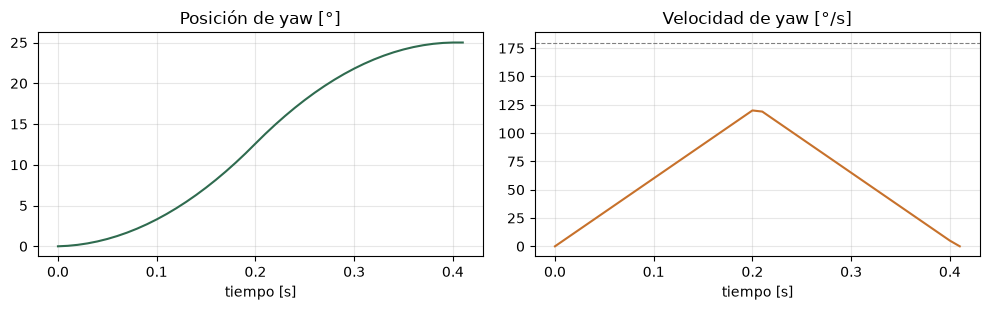

Llega a 25° en 0.41 s · vmax = 180.0 °/s · amax = 600.0 °/s²


In [3]:
# Simulación con el generador de trayectorias del robot (el firmware ejecuta la misma lógica a 100 Hz).
from keepon.trajectory import Neck
neck = Neck.from_config(cfg)
neck.set_target(25.0, 0.0, 0.0)          # girar 25° en yaw
t, pos = [0.0], [neck.pos[0]]
while neck.moving():
    neck.step(0.01)
    t.append(t[-1] + 0.01); pos.append(neck.pos[0])
vel = [0.0] + [(b - a) / 0.01 for a, b in zip(pos, pos[1:])]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(t, pos, color="#2f6b4f"); ax[0].set_title("Posición de yaw [°]"); ax[0].set_xlabel("tiempo [s]")
ax[1].plot(t, vel, color="#c7712b"); ax[1].set_title("Velocidad de yaw [°/s]"); ax[1].set_xlabel("tiempo [s]")
ax[1].axhline(cfg["neck"]["vmax"][0], ls="--", color="gray", lw=0.8)
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"Llega a 25° en {t[-1]:.2f} s · vmax = {cfg['neck']['vmax'][0]} °/s · amax = {cfg['neck']['amax'][0]} °/s²")

### Seguridad

| Mecanismo | Qué hace | Por qué |
|---|---|---|
| **Watchdog 500 ms** | Sin comandos válidos durante 500 ms, la ESP32 corta el sonido, frena y mantiene la postura. La Pi manda `PING` cada 200 ms. | Si la Pi se cuelga o se desconecta el USB, el robot no queda moviéndose. |
| **STOP enclavado** | Frena suave, corta el sonido y rechaza movimientos y sonidos hasta `RESUME`. | Máxima prioridad; ningún comportamiento lo puede liberar solo. |
| **Pulso permanente** | En STOP y watchdog se sigue mandando el último pulso. | El MG996R sin pulso queda flojo y la cabeza caería. |
| **Arranque en HOME** | Al encender arranca en HOME y avisa con `HELLO 0`. | Sin realimentación, la única postura conocida es la primera que se manda. |

### Firmware y protocolo serie

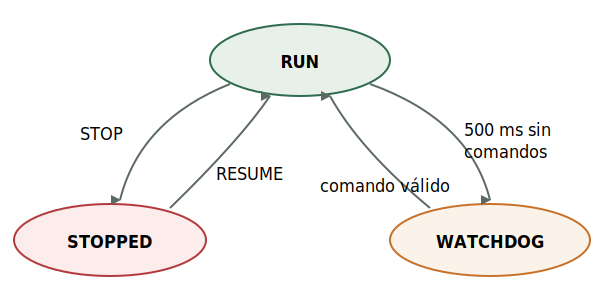

| Comando (Pi → ESP32) | Efecto |
|---|---|
| `HELLO 1` | Abre la sesión |
| `J seq yaw pitch roll` | Nueva referencia articular (reemplaza a la anterior) |
| `S seq NOMBRE` | Reproduce un sonido; la ESP32 avisa `DONE` al terminar |
| `CANCEL seq SOUND` | Corta el sonido |
| `PING seq` | Keepalive; responde `STATE` con estado, ángulos y sonido |
| `STOP seq` / `RESUME seq` | STOP enclavado / liberarlo |
| `HOME seq` | Va a HOME con rampa |
| `VOL seq PCT` | Volumen del buzzer 0–100 % |

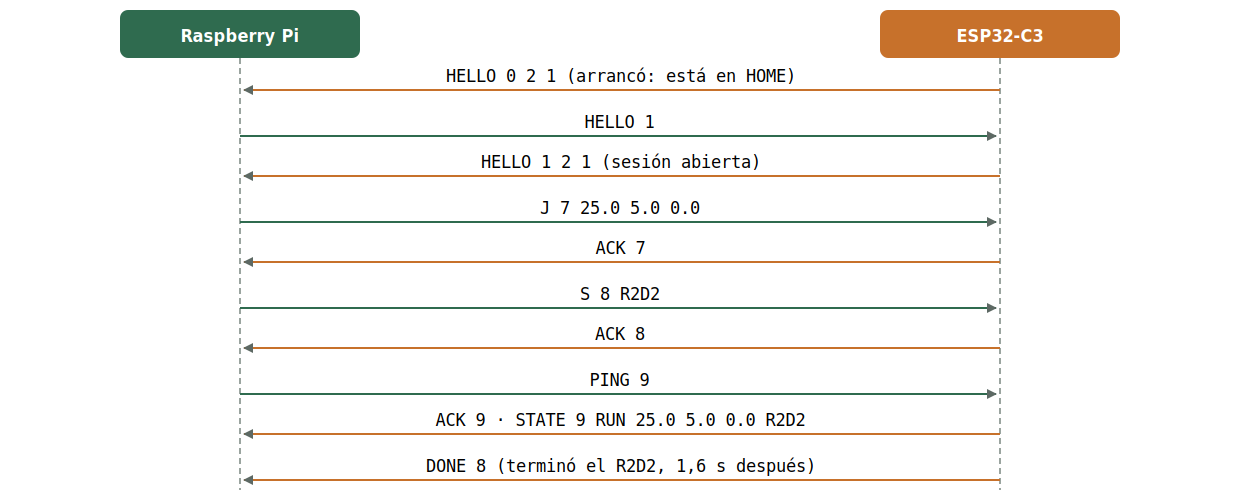

*Figura 7. Ejemplo de sesión. Si en plena sesión llega un `HELLO 0`, la ESP32 se reinició: la Pi cancela todo, toma HOME como referencia,
reabre la sesión y reenvía el STOP si estaba activo.*

**En la ESP32 real (14/10):** 30 de 30 pruebas OK; latencia PING → ACK de 4,4 ms (máx. 4,9); un movimiento a 70/30/−20 llega en 0,68 s
(el simulador dice 0,69 s); 304 KB de flash (23 %) y 14 KB de RAM (4 %).

### Historia de los servos

| Eje | Qué se probó | Resultado |
|---|---|---|
| yaw | Dos RDS3218 | El n.º 1 vibraba quieto cerca de 1500 µs; al intercambiarlos la vibración siguió al servo → descartado. |
| pitch | HS-7955TG → MG996R nuevo (05/11) | El HS es fuerte (18 kgf·cm) pero metía mucho ruido en la alimentación. |
| roll | MG996R n.º 1 → MG996R nuevo (05/11) | El n.º 1 tenía ~10° de banda muerta; se compensó en el firmware con 151 µs según el sentido. El nuevo vuelve a 0 sin compensación. |

Los servos **vibran moviéndose despacio** (avanzan a saltitos por la banda muerta) y no vibran quietos. Bajar la velocidad lo empeoró: por eso
el robot hace **movimientos rápidos y pocos** (ver la mirada por objetivo en la sección 7).

## 5. Modelos de IA y librerías utilizados

| Qué detecta | Modelo / librería | Fuente | Por qué este |
|---|---|---|---|
| Personas | **YOLO26n**, exportado a NCNN con entrada de 256 px, confianza 0,4 | Ultralytics, https://github.com/ultralytics/ultralytics | A 480 px tardaba 79 ms y saturaba la CPU; a 256 px tarda 18 ms y detecta a 2 de 2 personas a 1,5 m en el 100 % de los cuadros. |
| Rostros | **BlazeFace** (6 puntos) sobre un recorte de 192 px de la cabeza | Google MediaPipe, https://github.com/google-ai-edge/mediapipe | Face Landmarker (478 puntos) tardaba ~49 ms por cara y en la imagen completa encontraba solo 0,4–0,7 de 2 rostros. |
| Pose (hombros, muñecas) | **MediaPipe Pose** lite, hasta 2 personas | Google MediaPipe | Para el SALUDO y para ubicar el torso (camisetas). |
| Orientación de la cara | `cv2.solvePnP` con los 6 puntos de BlazeFace | OpenCV, https://opencv.org | Da el ángulo de la cara respecto de la cámara (ME_MIRA). |
| Inferencia | NCNN | Tencent, https://github.com/Tencent/ncnn | Rápido en CPU ARM. |
| Cámara | `camera_ros` (libcamera) sobre ROS 2 Jazzy | https://github.com/christianrauch/camera_ros | Era la forma que ya funcionaba en la Pi con Ubuntu 24.04. |

**Desarrollo propio del grupo:** tracker de personas (por solapamiento de cajas, IoU), filtros temporales de los eventos, detector de
camisetas, control de la mirada, foco de atención, comportamientos, árbitro, firmware y protocolo. (El ByteTrack de Ultralytics costaba
~68 ms por cuadro en la Pi; el tracker propio, casi nada.)

## 6. Definición operativa de cada evento

Un evento no se dispara por un cuadro suelto: cada uno tiene un umbral y un filtro temporal con histéresis (`keepon/eventos.py`).

| Evento | Condición en cada cuadro | Filtro temporal |
|---|---|---|
| **PERSONA** | Caja de YOLO de clase persona con confianza ≥ 0,4, asociada a un ID por el tracker. | Si el objetivo desaparece menos de 1 s se mantiene; después se libera. |
| **ME_MIRA** | Ángulo entre el eje de la cara y la línea cara → cámara < 15°. | Se activa tras 0,5 s seguidos mirando; se suelta tras 0,3 s sin mirar. |
| **SALUDO** | Muñeca al menos 0,1 anchos de hombros por encima del hombro, oscilando de costado con amplitud ≥ 0,25 anchos de hombros (en hombros, para no depender de la distancia). | 2 ciclos dentro de 2,5 s → un evento. Para contar otro, la mano tiene que bajar 0,4 s (un gesto = una respuesta). Cooldown 5 s por persona. |
| **CAMISETA_OLIMPIA / CERRO** | Clase del torso según reglas de color y patrón (abajo). | 6 cuadros seguidos para confirmar y 6 para soltar, por persona. Cooldown 25 s por persona. |
| **SALIENDO** | A menos del 15 % del ancho del borde y alejándose a ≥ 80 px/s, o el yaw a menos de 4° de su límite con la persona más allá del centro. | Se activa si dura 0,2 s; se suelta tras 0,6 s. |

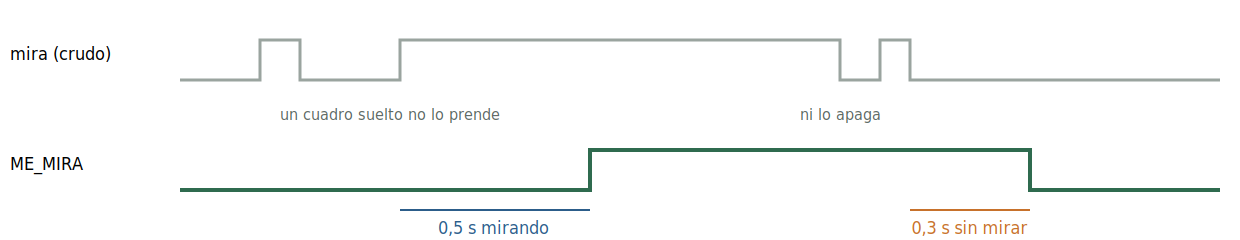

*Figura 8. Histéresis temporal de ME_MIRA: un cuadro suelto no lo prende ni lo apaga.*

### Detector de camisetas (reglas de color y patrón)

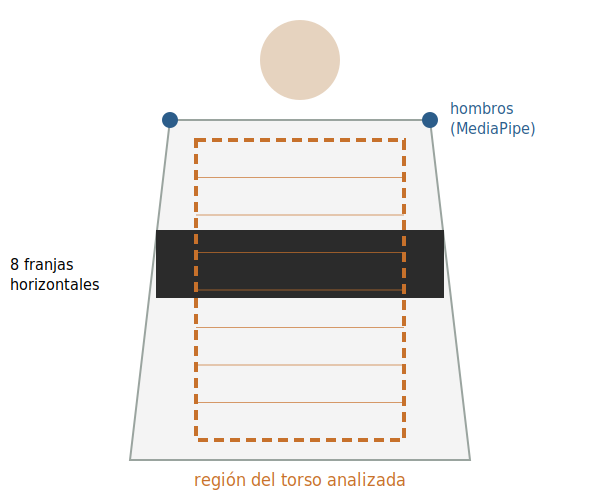

1. **Ubicar el torso** con los hombros de MediaPipe: de 0,15 a 1,1 anchos de hombros debajo de ellos, sin el 10 % de cada lado (brazos).
   Se exigen hombros visibles, ≥ 40 px de ancho y ≥ 40 % del torso dentro del cuadro.
2. **Clasificar cada píxel** en HSV (rojo, azul, blanco, oscuro) con umbrales medidos con la cámara NoIR sobre las prendas reales.
3. **Buscar el patrón:**
   - **Olimpia:** el torso en 8 franjas horizontales; una oscura (brillo ≤ 110) con franjas blancas (saturación ≤ 60) arriba y abajo, al menos 1,6 veces más claras.
   - **Cerro:** el torso en 8 columnas; al menos 2 rojas y 2 azules separadas por un borde vertical, y ≥ 20 % de píxeles de cada color.
     No se exigen rayas porque la titular 2026 es mitad roja y mitad azul.
   - **Nada:** lo demás. Las remeras lisas rojas, azules o blancas no cumplen ningún patrón.

**Resultados con la cámara del robot (04/11, tomas de 60 s a 1,2 / 1,8 / 2,5 m):**

| Toma | Detectada tras el filtro | Falsos positivos |
|---|---|---|
| Olimpia titular | 82 % (99 % desde los 10 s) | 0 % |
| Cerro 2026, mitad y mitad | 98 % | 0 % |
| Remera roja lisa | — | 0 % |
| Remera azul marino lisa | — | 0 % |
| Remera blanca lisa | Solo probada con una imagen sintética | — |

Limitación conocida: la camiseta del Barcelona es casi igual a la de Cerro por color y patrón.

## 7. Arquitectura

Todo corre en la Pi en Python puro; ROS 2 solo entrega la imagen de la cámara. La percepción va en **2 procesos** fijados a núcleos y el
lazo de decisión y control corre a 40 Hz.

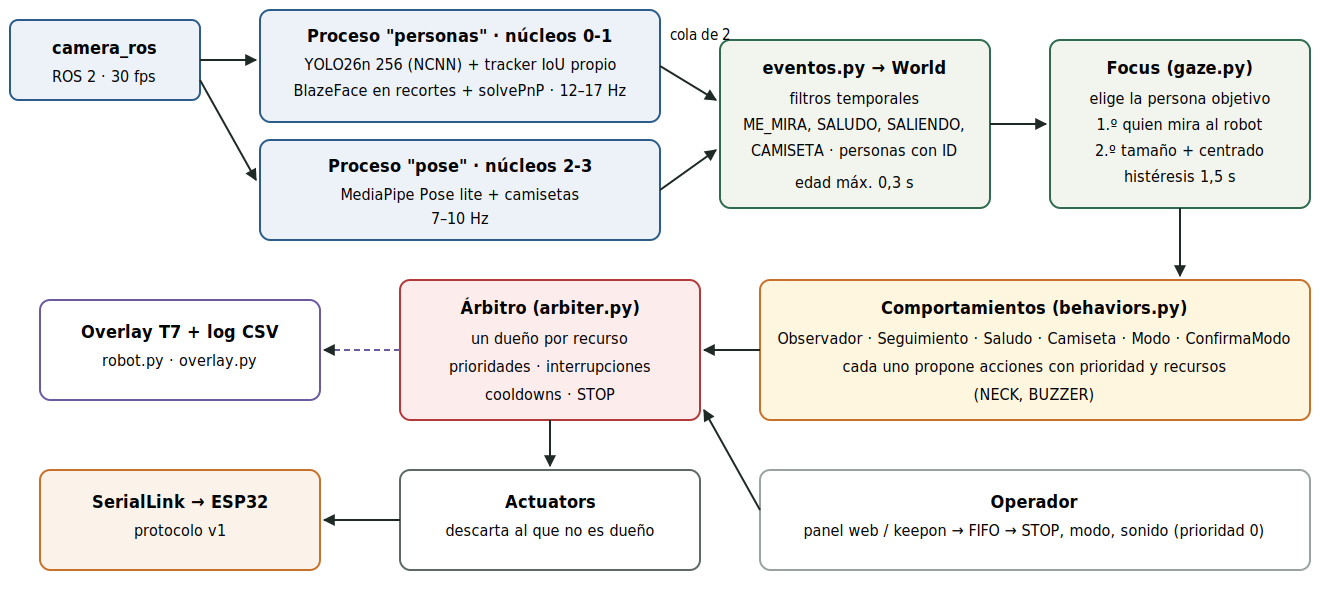

*Figura 9. Flujo de datos. La percepción manda siempre el último resultado por una cola de tamaño 2 y nunca bloquea el lazo.
Un dato de más de 0,3 s se considera sin datos.*

| Módulo | Qué hace |
|---|---|
| `perception.py` | Proceso "personas" (YOLO + tracker + rostros + solvePnP, núcleos 0-1) y proceso "pose" (MediaPipe + camisetas, núcleos 2-3). |
| `eventos.py`, `camiseta.py` | De percepción cruda (cuadro a cuadro) a eventos filtrados en el tiempo. |
| `world.py` | Modelo del mundo: personas con ID, caja, rostro, eventos activos y antigüedad del dato. |
| `gaze.py` | Control de la mirada y foco de atención. |
| `behaviors.py`, `arbiter.py`, `actuators.py` | Comportamientos, árbitro de recursos y filtro de comandos por dueño. |
| `trajectory.py`, `protocol.py`, `link.py`, `sim_esp32.py` | Trayectorias, protocolo, enlace serie (real o simulado) y la ESP32 simulada, que es la especificación del firmware. |
| `robot.py`, `overlay.py` | Lazo principal, resincronización si la ESP32 se reinicia, log CSV y overlay de monitoreo. |
| `firmware/keepon_fw/` | Firmware de la ESP32-C3: núcleo portable en C++ + capa de hardware Arduino. |

**¿Por qué procesos y no hilos?** NCNN y MediaPipe no liberan el GIL de Python: con hilos tardaban casi lo mismo que en serie (2,04 s contra 2,11 s).

### Control de la mirada

El error angular de la cara respecto del centro óptico es `atan((u − cx) / fx)` en yaw y `atan((v − cy) / fy)` en pitch
(con fx ≈ 948 px, 1° ≈ 16,5 px). La cámara apunta 8° por debajo de la cara para que entre la camiseta.

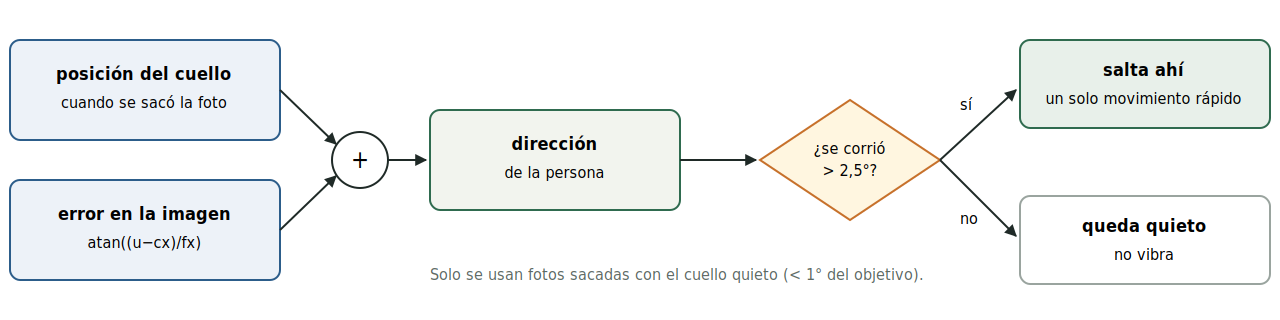

*Figura 10. Mirada por objetivo: dirección de la persona = posición del cuello **cuando se sacó la foto** + error en la imagen. La
referencia salta ahí en un solo movimiento rápido si la persona se corrió más de 2,5°, y si no queda quieta. Esto compensa el atraso de la
percepción (~100–135 ms) y evita la vibración de los movimientos lentos. El control proporcional en velocidad anterior
(velocidad = kp × (|error| − zona muerta), con saturación y suavizado) queda como respaldo en `config.yaml`.*

### Foco de atención

| Regla | Detalle |
|---|---|
| 1. Quien mira al robot | Prioridad estricta: una persona con ME_MIRA gana siempre. |
| 2. Si nadie mira | Puntaje = 0,6 × tamaño + 0,4 × centrado. |
| 3. Histéresis | Un candidato tiene que ser mejor durante 1,5 s seguidos para quitarle el foco al actual. |
| 4. Pérdida breve | Si el objetivo desaparece menos de 1 s se mantiene la mirada; después se libera. |

## 8. Tabla de prioridades, recursos e interrupciones

Hay dos recursos exclusivos: el **cuello** (NECK) y el **buzzer** (BUZZER). Cada comportamiento propone acciones y el árbitro decide quién es
dueño de cada recurso en cada instante (`keepon/arbiter.py`, desarrollo propio).

| Prioridad | Comportamiento | Recursos | Lo puede interrumpir | Qué hace |
|---|---|---|---|---|
| 0 | **OPERADOR** | todos | nadie | STOP enclavado, HOME, sonidos, beep de cambio de modo |
| 1 | **SALUDO** | cuello + buzzer | solo el operador | 3 cabeceos de 12° + R2D2 |
| 2 | **CAMISETA** | buzzer | operador o saludo | Polca (Olimpia) o abucheo (Cerro) |
| 3 | **MODO** | cuello o buzzer | los más importantes | Reacción del modo de personalidad |
| 4 | **SEGUIMIENTO** | cuello | cualquiera más importante | Mantener la mirada en la persona objetivo (continuo) |
| 5 | **OBSERVADOR** | cuello | cualquiera más importante | Explorar sin personas (continuo) |

**Reglas del árbitro:**
1. **Exclusividad:** cada recurso tiene a lo sumo un dueño.
2. **Prioridad:** número menor = más importante. Una propuesta solo le quita un recurso a un dueño menos importante *y* que acepte ser interrumpido por ella.
3. **Atomicidad:** se conceden todos los recursos pedidos o ninguno; si a una acción le quitan un recurso, se cancela entera.
4. **Vencimiento y cooldown:** las propuestas viejas o en cooldown se descartan; el cooldown cuenta desde que la acción empieza.
5. **Continuas y episódicas:** seguir y observar retienen el cuello mientras se vuelvan a proponer; saludo y polca, hasta que terminan.
6. **STOP** cancela todo, incluso lo no interrumpible, y queda enclavado hasta RESUME.

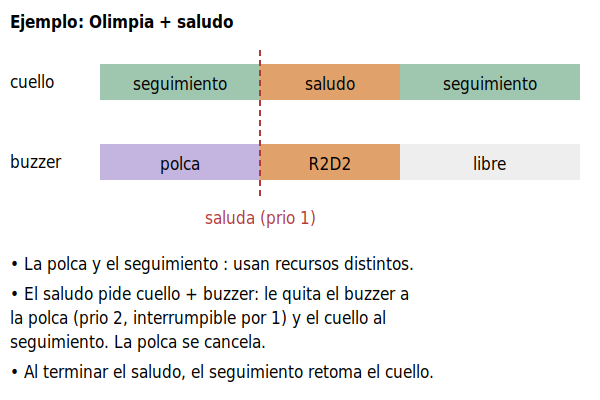

*Figura 11. Ejemplo: la polca y el seguimiento conviven porque usan recursos distintos. Un saludo pide cuello + buzzer: le quita el buzzer a la
polca y el cuello al seguimiento; al terminar, el seguimiento retoma el cuello.*

**Una sola orden coherente al cuello:** `Actuators` descarta cualquier comando de quien no es dueño del recurso, así que nunca hay dos controladores
escribiendo al cuello. La curiosidad y los gestos de los modos se calculan dentro del dueño del cuello.

In [4]:
# Prioridades y cooldowns tal como están en config.yaml.
display(pd.DataFrame({"prioridad": cfg["priorities"]}).sort_values("prioridad"))
display(pd.DataFrame({"segundos": cfg["cooldowns"]}))

,prioridad
OPERADOR,0
SALUDO,1
CAMISETA,2
MODO,3
SEGUIMIENTO,4
OBSERVADOR,5


,segundos
SALUDO_por_persona,5.0
CAMISETA_por_persona,25.0
PIROPO_global,40.0


## 9. Diagramas de estados de los modos de personalidad

Se cambian en cualquier momento desde el panel del celular o con `keepon n|t|a|m`; cada cambio se confirma con un beep distinto. El modo inicial es Neutro.

| Modo | Disparador | Reacción | Beep |
|---|---|---|---|
| **Neutro** | — | Solo sostiene el contacto visual (seguimiento). | 0,25 s |
| **Tímido** | ME_MIRA | Aparta la mirada 25° al costado con más lugar, 12° abajo y 10° de roll; la sostiene 2,5 s y vuelve a espiar en 3 s con una curva suave. | 0,35 s |
| **Atrevido** | ME_MIRA | Levanta el mentón 10°, 3 veces (período 1,2 s), sin dejar de seguir en yaw. | 0,35 s |
| **Maleducado** | SALIENDO | Silbido de piropo, una vez por salida y como mucho uno cada 40 s entre todos. | 0,45 s |

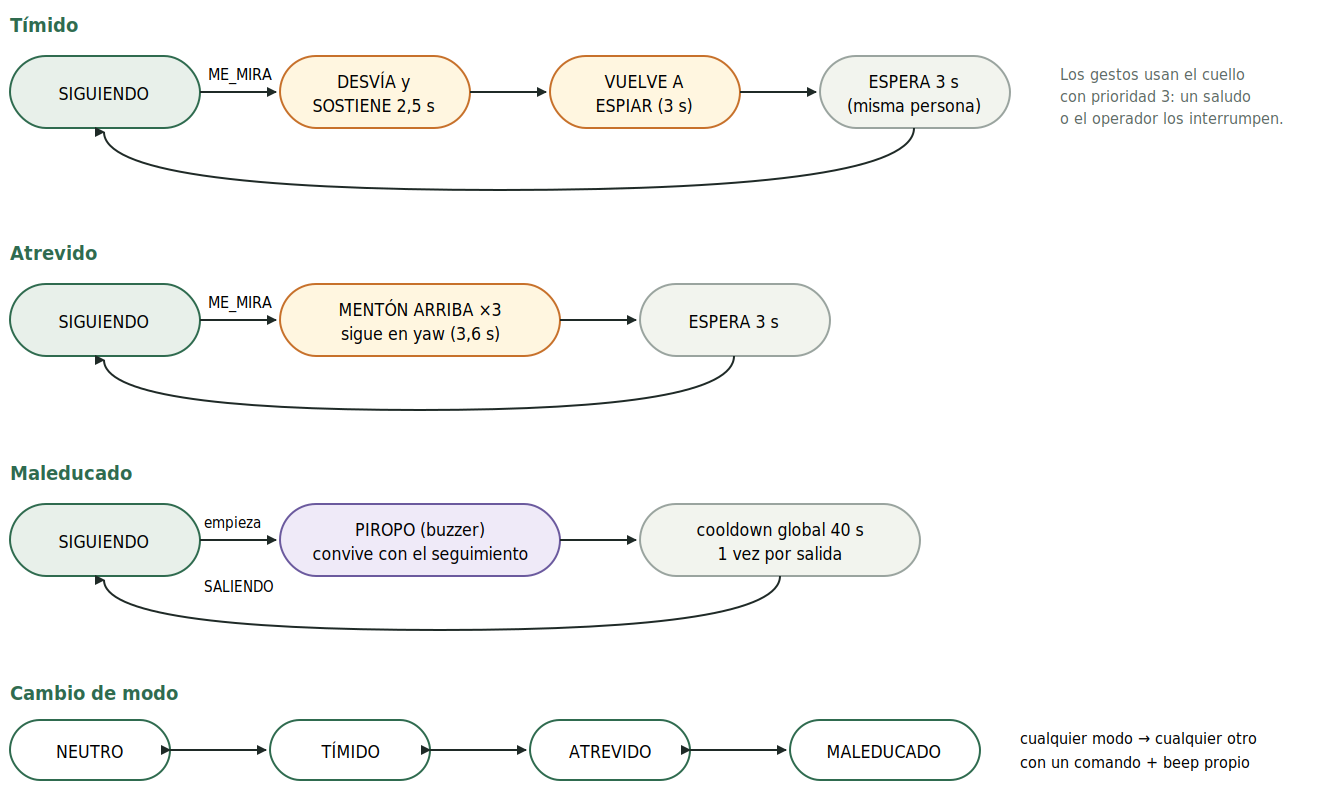

*Figura 12. Diagramas de estados. Las esperas son cooldowns por persona (Tímido, Atrevido) o global (piropo). Los gestos usan el cuello con
prioridad 3: un saludo o el operador los interrumpen.*

### Sonidos

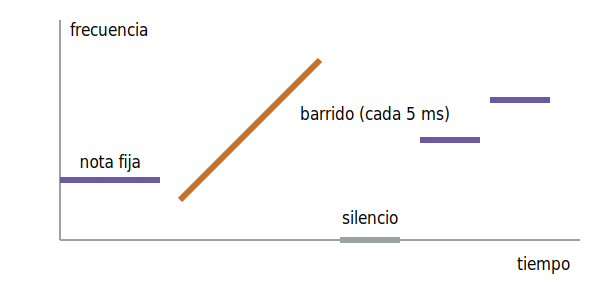

Cada sonido es una tabla de segmentos `{frecuencia inicial, frecuencia final, ms}` (nota fija, barrido lineal o silencio) que la ESP32
reproduce sin bloquear. La polca de Olimpia se transcribió a mano de la partitura: compases 1 a 8, 7,1 s, una octava más arriba de lo escrito
porque abajo el buzzer suena débil.

In [5]:
# Duración de cada sonido [s] (sounds de config.yaml; el firmware avisa DONE al terminar).
display(pd.DataFrame({"duración [s]": cfg["sounds"]}))

,duración [s]
R2D2,1.600
POLCA,7.104
POLCA_CERRO,6.000
ABUCHEO,2.500
PIROPO,1.200
DESAPROBACION,0.800
BEEP_NEUTRO,0.250
BEEP_TIMIDO,0.350
BEEP_ATREVIDO,0.350
BEEP_MALEDUCADO,0.450


## 10. Parámetros utilizados

Todos los parámetros están en `config.yaml`. Las tablas siguientes se leen directamente de ese archivo.

In [6]:
def tabla(seccion, claves=None):
    d = cfg[seccion]
    filas = {k: (str(v) if isinstance(v, (list, dict)) else v) for k, v in d.items() if claves is None or k in claves}
    return pd.DataFrame({"valor": filas})

print("Cuello: límites [°], velocidad máxima [°/s] y aceleración máxima [°/s²] por eje (yaw, pitch, roll)")
display(tabla("neck", ["limits", "home", "vmax", "amax"]))
print("Percepción")
display(tabla("perception", ["yolo_imgsz", "yolo_conf", "face_model", "face_crop_px", "looking_deg", "max_age_s", "cores_personas", "cores_pose"]))
print("Eventos: umbrales y filtros temporales")
display(tabla("eventos"))

Cuello: límites [°], velocidad máxima [°/s] y aceleración máxima [°/s²] por eje (yaw, pitch, roll)


,valor
limits,"{'yaw': [-70.0, 70.0], 'pitch': [-20.0, 30.0], 'roll': [-20.0, 20.0]}"
home,"[0.0, 0.0, 0.0]"
vmax,"[180.0, 120.0, 120.0]"
amax,"[600.0, 400.0, 300.0]"


Percepción


,valor
max_age_s,0.3
yolo_imgsz,256
yolo_conf,0.4
face_model,detector
face_crop_px,192
cores_personas,"[0, 1]"
cores_pose,"[2, 3]"
looking_deg,15.0


Eventos: umbrales y filtros temporales


,valor
mira_sostenida_s,0.50
mira_suelta_s,0.30
saludo_ciclos,2.00
saludo_ventana_s,2.50
saludo_amp_hombros,0.25
saludo_margen_hombros,0.10
saludo_mano_abajo_s,0.40
pose_vis_min,0.50
saliendo_borde_frac,0.15
saliendo_vel_px_s,80.00


In [7]:
print("Mirada (gaze) y foco de atención (focus)")
display(tabla("gaze"))
display(tabla("focus"))
print("Modos de personalidad, saludo y curiosidad")
display(pd.json_normalize(cfg["modos"], sep=".").T.rename(columns={0: "valor"}))
display(tabla("greeting"))
display(tabla("curiosidad"))

Mirada (gaze) y foco de atención (focus)


,valor
modo,objetivo
umbral_deg,"[2.5, 2.5]"
quieto_deg,1.0
kp,"[4.0, 2.5]"
vmax,"[150.0, 90.0]"
deadzone,0.03
ema,"[0.5, 0.3]"
lost_hold_s,1.0
mirar_abajo_deg,8.0


,valor
switch_after_s,1.5
w_looking,1.0
w_size,0.6
w_center,0.4


Modos de personalidad, saludo y curiosidad


,valor
inicial,NEUTRO
timido.desvio_yaw_deg,25.0
timido.desvio_pitch_deg,12.0
timido.desvio_roll_deg,10.0
timido.sostener_s,2.5
timido.regreso_s,3.0
timido.espera_s,3.0
atrevido.menton_deg,10.0
atrevido.periodo_s,1.2
atrevido.veces,3


,valor
nods,3.0
nod_amp,12.0
nod_period_s,1.0


,valor
activa,True
quieto_s,3.0
movimiento_max_deg,5.0
amp_deg,15.0
sostener_s,2.0
espera_s,8.0


In [8]:
print("Detector de camisetas")
display(tabla("camiseta"))

Detector de camisetas


,valor
vis_min,0.5
ancho_min_px,40
margen_lados,0.1
desde_hombros,0.15
hasta_hombros,1.1
visible_min,0.4
rojo,"{'h_max': 8, 'h_min': 165, 's_min': 120, 'v_min': 60}"
azul,"{'h_min': 100, 'h_max': 160, 's_min': 25, 'v_min': 15, 'v_max': 130}"
columnas,8
col_dominante,0.5


## 11. Resultados y pruebas de funcionamiento

### Frecuencia de la percepción (Raspberry Pi 5)

La celda siguiente grafica los benchmarks guardados en el repositorio (30/09, en la Pi). Muestran el problema inicial: con todo en serie no se
llegaba a 10 Hz con personas en escena. La solución fue YOLO a 256 px y 2 procesos en paralelo.

,escena,configuración,imgsz,yolo_ms,face_ms,pose_ms,Hz procesados,edad del cuadro [ms],CPU [%]
0,sin personas,A_yolo480_t4,480,79.0,0.0,0.0,11.2,109.8,283
1,sin personas,A_yolo480_t2,480,88.6,0.0,0.0,10.6,126.3,252
2,sin personas,A_yolo320_t4,320,31.7,0.0,0.0,22.5,50.1,251
3,sin personas,A_yolo320_t2,320,45.4,0.0,0.0,17.3,67.6,223
4,sin personas,A_yolo256_t4,256,18.2,0.0,0.0,29.9,33.8,201
5,sin personas,A_yolo256_t2,256,36.0,0.0,0.0,17.1,54.1,177
6,sin personas,B_mediapipe,320,0.0,5.7,32.6,25.7,67.9,126
7,sin personas,C_full320_t2,320,49.5,6.0,34.2,11.1,122.2,202
8,sin personas,C_full320_t3,320,49.0,6.0,34.6,11.1,120.9,213
9,sin personas,C_full256_t2,256,34.2,6.0,33.8,13.4,105.0,185


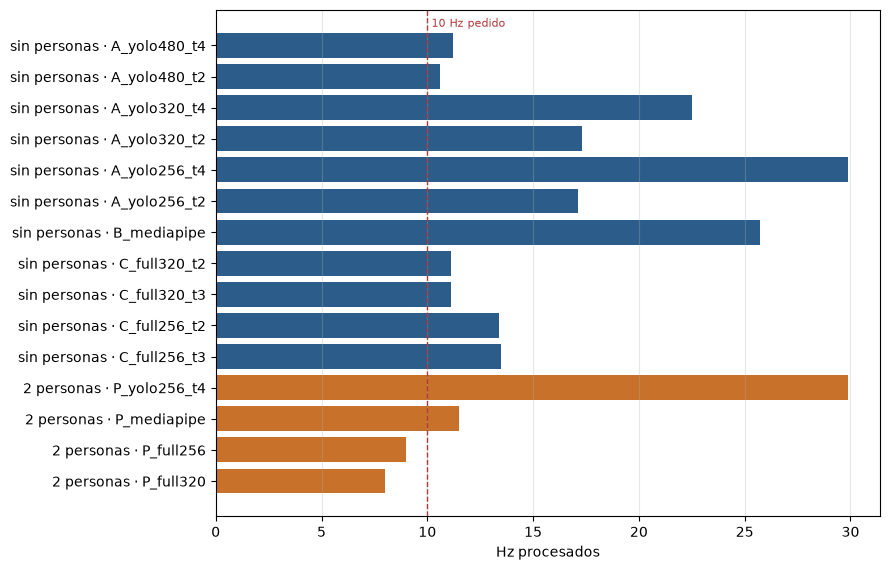

In [9]:
b0 = pd.read_csv("keepon-pro/docs/benchmark_pi_20260930_sin_personas.csv")
b2 = pd.read_csv("keepon-pro/docs/benchmark_pi_20260930_2personas.csv")
b0["escena"], b2["escena"] = "sin personas", "2 personas"
b = pd.concat([b0, b2])
cols = ["escena", "label", "imgsz", "yolo_ms", "face_ms", "pose_ms", "proc_hz", "edad_ms", "cpu_pct"]
display(b[cols].rename(columns={"label": "configuración", "proc_hz": "Hz procesados", "edad_ms": "edad del cuadro [ms]", "cpu_pct": "CPU [%]"}))

fig, ax = plt.subplots(figsize=(9, 0.32 * len(b) + 1))
etiquetas = [f"{e} · {l}" for e, l in zip(b["escena"], b["label"])]
ax.barh(etiquetas, b["proc_hz"], color=["#2c5d8a" if e == "sin personas" else "#c7712b" for e in b["escena"]])
ax.axvline(10, color="#b23a3a", ls="--", lw=1); ax.text(10.2, -0.6, "10 Hz pedido", color="#b23a3a", fontsize=8)
ax.set_xlabel("Hz procesados"); ax.invert_yaxis(); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

**Con la arquitectura final en el robot real** (percepción en 2 procesos, robot completo funcionando):

| Medida | Valor |
|---|---|
| Lazo de control y árbitro | 36–39 Hz |
| Detección de personas + rostros | **12–17 Hz** (pedido: ≥ 10 Hz) |
| Pose (saludo, camisetas) | 7–10 Hz |
| Edad del cuadro al decidir | 96–135 ms |
| Latencia serie PING → ACK | 4,4 ms |
| Latencia evento → inicio de la respuesta | <span style="background:#fff3b0;padding:2px 4px">**[A COMPLETAR POR EL GRUPO]**</span> (estimación por suma de tiempos: ≈ 130–170 ms; pedido: ≤ 300 ms) |

### Requisitos de la consigna

| Requisito | Resultado |
|---|---|
| Percepción ≥ 10 Hz | Cumple en personas (12–17 Hz); la pose queda en el límite (7–10 Hz). |
| Latencia evento → respuesta ≤ 300 ms | Estimada en ≈ 130–170 ms; medición de punta a punta <span style="background:#fff3b0;padding:2px 4px">**[A COMPLETAR POR EL GRUPO]**</span>. |
| Todo no bloqueante | Firmware sin `delay()`; percepción en procesos; colas que descartan lo viejo. |
| Recursos exclusivos | 0 violaciones en el escenario simulado de 30 s (abajo). |
| Prioridades, cooldowns, histéresis | 6 prioridades; cooldowns de 5 / 25 / 40 s; histéresis de foco de 1,5 s y filtros por evento. |
| Overlay y log con marca de tiempo | Overlay con personas e ID, objetivo, eventos, modo, dueño de cada recurso y ángulos; log CSV de transiciones. |

### Escenario simulado de 30 s

La celda siguiente corre el escenario del repositorio: personas sintéticas que aparecen, se mueven, saludan y llevan camiseta, con el árbitro,
los comportamientos y el control reales contra la ESP32 simulada. Grafica los ángulos del cuello y quién es dueño de cada recurso en cada momento.

[   0.03] ESP32 sesión abierta fw=2
[   0.03] ARB start OBSERVADOR#1 persona=None recursos=NECK
[   4.45] FOCO None -> 1
[   4.45] ARB stop  OBSERVADOR#1 (interrumpido por SEGUIMIENTO)
[   4.45] ARB start SEGUIMIENTO#2 persona=1 recursos=NECK
[   8.00] ARB stop  SEGUIMIENTO#2 (interrumpido por SALUDO)
[   8.00] ARB start SALUDO#3 persona=1 recursos=BUZZER+NECK
[  11.02] ARB stop  SALUDO#3 (fin)
[  11.05] ARB start SEGUIMIENTO#4 persona=1 recursos=NECK
[  11.50] ARB start CAMISETA#5 persona=1 recursos=BUZZER
[  13.50] ARB stop  CAMISETA#5 (interrumpido por SALUDO)
[  13.50] ARB stop  SEGUIMIENTO#4 (interrumpido por SALUDO)
...
[  23.02] ARB resume
[  23.02] ARB start SEGUIMIENTO#9 persona=2 recursos=NECK
[  27.02] FOCO 2 -> None
[  27.02] ARB stop  SEGUIMIENTO#9 (sin propuesta)
[  27.05] ARB start OBSERVADOR#10 persona=None recursos=NECK

violaciones de recursos: 0
gráfico: /tmp/claude-1000/-home-hecvelaz-Documentos-Keepon-pro-/fbc6757f-a644-4d69-b04a-2adf21c7c154/scratchpad/ejec/keepon

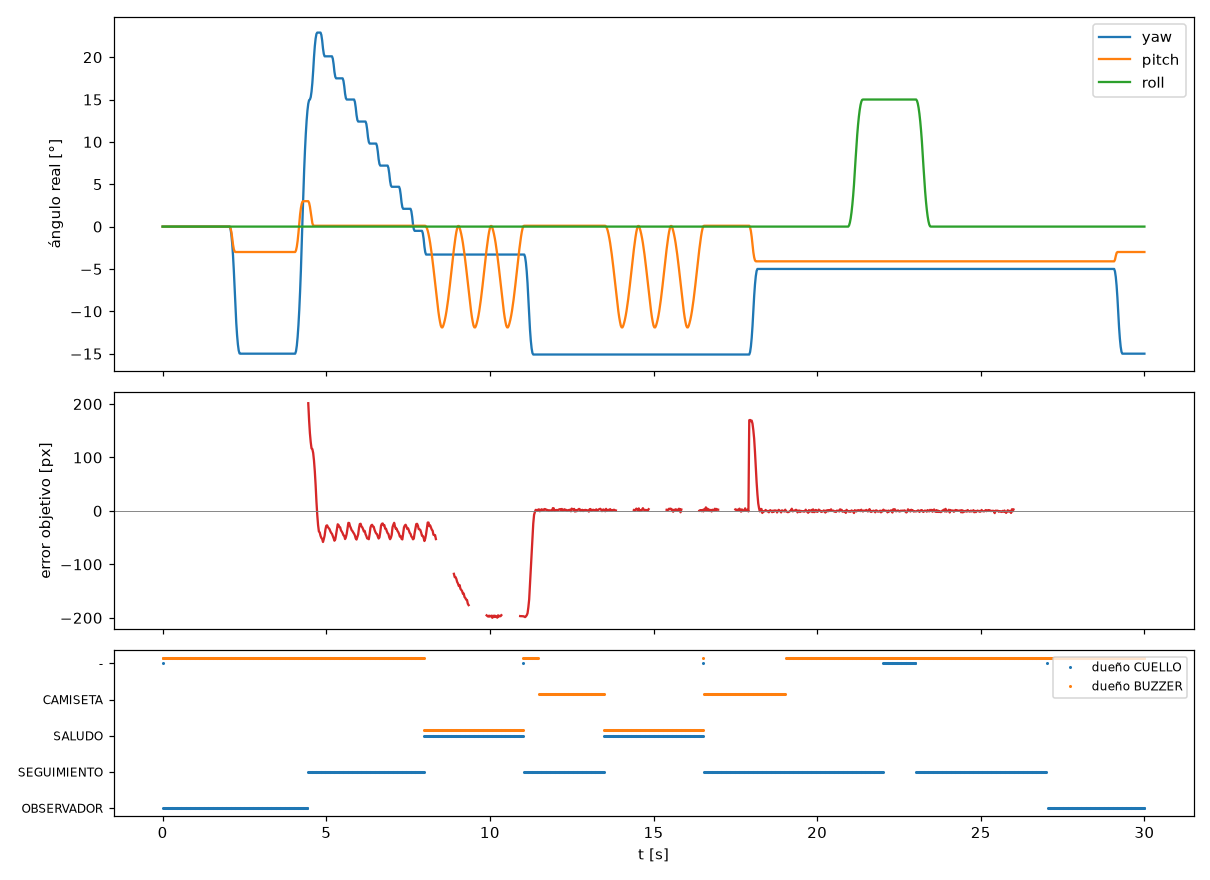

In [10]:
import subprocess
from IPython.display import Image as Imagen, display
r = subprocess.run([sys.executable, "keepon-pro/scripts/sim_scenario.py", "--plot"], capture_output=True, text=True)
lineas = r.stdout.strip().splitlines()
print("\n".join(lineas[:12] + ["..."] + lineas[-8:]))
display(Imagen("keepon-pro/logs/sim_scenario.png"))

### Pruebas automáticas

| | |
|---|---|
| Tests con pytest | **219** |
| Firmware contra simulador (paso a paso, con fuzzing) | 36+ |
| Pruebas en la ESP32 real | 30 / 30 |
| Fallos encontrados por una revisión externa del código | 8, cada uno con su test de regresión |

Un bug real que encontraron las pruebas: el firmware daba watchdog y fines de sonido falsos al restar tiempos sin signo. Se corrigió y quedó
como test de regresión: después, 6 minutos de robot real sin ningún watchdog.

### Funciones probadas en el robot

| Probado en el robot real | Implementado, falta probar en el robot | Falta |
|---|---|---|
| Seguimiento con foco e histéresis · Observador · Saludo (3 cabeceos + R2D2) · Olimpia → polca mientras sigue · Cerro → abucheo · lisas sin falsos positivos · cambio de modo con beep · curiosidad · apagar a HOME · overlay y log · panel del celular | Mirada por objetivo y Observador por miradas (05/11) · Tímido · Atrevido · Maleducado con SALIENDO · signo del roll · STOP en pleno movimiento · varias personas a la vez | Medir la latencia · calibrar la cámara con tablero · remera blanca real |

<span style="background:#fff3b0;padding:2px 4px">**[A COMPLETAR POR EL GRUPO]**</span> Actualizar esta tabla con lo que se pruebe antes de la entrega y con lo que muestra el video.

## 12. Aportes individuales

La consigna pide que la contribución de cada integrante sea clara (un set de features, detecciones, comportamientos, control, etc.).

| Integrante | Aporte principal |
|---|---|
| <span style="background:#fff3b0;padding:2px 4px">**[A COMPLETAR POR EL GRUPO]**</span> | |
| <span style="background:#fff3b0;padding:2px 4px">**[A COMPLETAR POR EL GRUPO]**</span> | |
| <span style="background:#fff3b0;padding:2px 4px">**[A COMPLETAR POR EL GRUPO]**</span> | |
| <span style="background:#fff3b0;padding:2px 4px">**[A COMPLETAR POR EL GRUPO]**</span> | |
| <span style="background:#fff3b0;padding:2px 4px">**[A COMPLETAR POR EL GRUPO]**</span> | |

**Uso de herramientas de IA:** la consigna permite usar IA para el desarrollo siempre que se comprenda el proceso y el resultado. <span style="background:#fff3b0;padding:2px 4px">**[A COMPLETAR POR EL GRUPO]**</span>
(describir brevemente cómo se usó).

## 13. Referencias y enlaces

- Repositorio con el código completo, el firmware, el CAD y la documentación: https://github.com/HecVelaz/keepon-pro
  (README con instalación, ejecución y comandos de modo y STOP).
- Guía completa del proyecto con más diagramas: `docs/guia/Guia_Keepon_pro.pdf`.
- Por qué se tomó cada decisión: `docs/DECISIONES.md`. Historia del trabajo: `docs/BITACORA.md`. Protocolo serie: `docs/PROTOCOLO.md`.
- Ultralytics YOLO: https://github.com/ultralytics/ultralytics
- Google MediaPipe (BlazeFace, Pose): https://github.com/google-ai-edge/mediapipe
- OpenCV: https://opencv.org · NCNN: https://github.com/Tencent/ncnn · camera_ros: https://github.com/christianrauch/camera_ros